# 02 · Pipeline y comparación de modelos

**Proyecto:** Alerta temprana de abandono de clientes (Telco Customer Churn)
**Curso:** Machine Learning · Maestría en Ciencia de Datos e Inteligencia Artificial · EPG UNAJ
**Docente:** Dr. Alain Paul Herrera Urtiaga
**Equipo:** Leydy Mayumy Coyllo Mamani · Noe Wilber Tipo Mamani · Jose Alfonso Nina Condori
**Producto:** 1

> **Pregunta del proyecto:** con los datos actuales de un cliente, ¿qué clientes cancelarán su servicio?

**Objetivo de este notebook:** construir un Pipeline sin fuga de datos, comparar los 5 modelos obligatorios con validación cruzada y evaluar el mejor, una sola vez, en el test.

In [1]:
# Configuración común (el notebook es autocontenido: corre en local y en Google Colab)
import warnings
warnings.filterwarnings("ignore")
import importlib, subprocess, sys
for _paquete in ["lightgbm"]:
    try:
        importlib.import_module(_paquete)
    except ImportError:  # en Colab puede faltar alguna librería
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _paquete], check=True)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
URL_CSV = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RUTA_LOCAL = Path("../data/Telco-Customer-Churn.csv")
EN_REPO = RUTA_LOCAL.exists()
RES = Path("../resultados") if EN_REPO else Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: azul = no abandona, naranja = abandona
AZUL, NARANJA, AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")

def guardar_json(obj, nombre):
    (RES / nombre).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

print("Datos locales:" if EN_REPO else "Datos desde la URL pública:", RUTA_LOCAL if EN_REPO else URL_CSV)

Datos locales: ../data/Telco-Customer-Churn.csv


In [2]:
# Carga y traducción al español (misma lógica que src/churn/datos.py)
MAPEO_COLUMNAS = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja",
    "Dependents": "tiene_dependientes",
    "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico",
    "MultipleLines": "lineas_multiples",
    "InternetService": "servicio_internet",
    "OnlineSecurity": "seguridad_en_linea",
    "OnlineBackup": "respaldo_en_linea",
    "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico",
    "StreamingTV": "tv_streaming",
    "StreamingMovies": "peliculas_streaming",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_electronica",
    "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    "Churn": "abandona",
}

MAPEO_VALORES = {
    "Yes": "Sí",
    "No": "No",
    "No internet service": "Sin internet",
    "No phone service": "Sin teléfono",
    "Month-to-month": "Mensual",
    "One year": "Un año",
    "Two year": "Dos años",
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
    "Male": "Hombre",
    "Female": "Mujer",
}

OBJETIVO = "abandona"
ID = "id_cliente"
NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
CATEGORICAS = [
    "genero", "adulto_mayor", "tiene_pareja", "tiene_dependientes",
    "servicio_telefonico", "lineas_multiples", "servicio_internet",
    "seguridad_en_linea", "respaldo_en_linea", "proteccion_dispositivo",
    "soporte_tecnico", "tv_streaming", "peliculas_streaming",
    "tipo_contrato", "factura_electronica", "metodo_pago",
]
# cargo_total se excluye del modelo por redundancia (≈ antigüedad × cargo mensual).
# La evidencia está en notebooks/02_modelos.ipynb y en DECISIONES.md.
EXCLUIDAS = [ID, "cargo_total"]
VARIABLES_MODELO = NUMERICAS + CATEGORICAS


def traducir(df: pd.DataFrame) -> pd.DataFrame:
    """Renombra columnas y traduce categorías. Acepta columnas en inglés o ya en español.

    No imputa: los blancos de ``cargo_total`` quedan como NaN.
    """
    df = df.rename(columns=MAPEO_COLUMNAS).copy()
    for col in df.columns:
        if col in (ID, OBJETIVO, "cargo_total") or col in NUMERICAS:
            continue
        if col == "adulto_mayor":
            df[col] = df[col].map(
                lambda v: "Sí" if str(v).strip() in ("1", "1.0", "Sí", "Si", "Yes")
                else ("No" if str(v).strip() in ("0", "0.0", "No") else np.nan)
            )
            continue
        if df[col].dtype == object or pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: MAPEO_VALORES.get(v, v) if isinstance(v, str) else v)
            if col == "servicio_internet":  # en esta columna "No" significa "sin internet"
                df[col] = df[col].replace({"No": "Sin internet"})
    if "cargo_total" in df.columns:
        df["cargo_total"] = pd.to_numeric(
            df["cargo_total"].astype(str).str.strip().replace("", np.nan), errors="coerce"
        )
    for col in NUMERICAS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if OBJETIVO in df.columns and not pd.api.types.is_numeric_dtype(df[OBJETIVO]):
        df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0, "Sí": 1}).astype(int)
    return df


def separar_X_y(df: pd.DataFrame):
    """Devuelve (X, y) con solo las variables que usa el modelo."""
    return df[VARIABLES_MODELO].copy(), df[OBJETIVO].astype(int).copy()

df_crudo = pd.read_csv(RUTA_LOCAL) if EN_REPO else pd.read_csv(URL_CSV)
df = traducir(df_crudo)
print(df.shape)

(7043, 21)


In [3]:
# Preprocesamiento dentro de un Pipeline (misma lógica que src/churn/preprocesamiento.py)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador(numericas=None, categoricas=None) -> ColumnTransformer:
    numericas = list(NUMERICAS if numericas is None else numericas)
    categoricas = list(CATEGORICAS if categoricas is None else categoricas)
    num = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", num, numericas), ("cat", cat, categoricas)],
        remainder="drop",
    )


def construir_pipeline(modelo, numericas=None, categoricas=None) -> Pipeline:
    """Pipeline completo: preprocesamiento + modelo."""
    return Pipeline([
        ("prep", construir_preprocesador(numericas, categoricas)),
        ("modelo", modelo),
    ])

## 1. Métrica de éxito

La métrica principal es el **recall** de la clase "abandona": de los clientes que realmente se van, ¿qué proporción detecta el modelo?

**Por qué:** los dos errores no cuestan lo mismo. Un *falso negativo* (no detectar a un cliente que se irá) significa perder todo el ingreso futuro de ese cliente. Un *falso positivo* (avisar de un cliente que se iba a quedar) solo cuesta una oferta de retención innecesaria (una llamada, un descuento). Como el primer error es mucho más caro, preferimos un modelo que detecte a la mayoría de los que se van, aunque genere algunas alertas de más.

Como el recall se puede "ganar" trivialmente marcando a todos como riesgo, reportamos siempre también **ROC-AUC** (capacidad de ordenar a los clientes por riesgo) y **PR-AUC** (precisión media; es más informativa que ROC-AUC cuando la clase positiva es minoritaria), además de la precisión.

## 2. División entrenamiento / test

In [4]:
# División 80/20 estratificada (la misma semilla en todos los notebooks)
from sklearn.model_selection import train_test_split
X, y = separar_X_y(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} filas · Test: {len(X_test)} filas · "
      f"abandono train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Entrenamiento: 5634 filas · Test: 1409 filas · abandono train 0.265 / test 0.265


In [5]:
guardar_json({"n_train": len(X_train), "n_test": len(X_test),
              "tasa_train": round(float(y_train.mean()), 4), "tasa_test": round(float(y_test.mean()), 4),
              "variables_modelo": VARIABLES_MODELO}, "02_division.json")

## 3. Cómo el Pipeline evita la fuga de datos

Todo el preprocesamiento está dentro de un `Pipeline` con un `ColumnTransformer`:

- **Numéricas** (`antiguedad_meses`, `cargo_mensual`): imputación por mediana + escalado estándar.
- **Categóricas** (16 variables): imputación por la moda + *one-hot* (`handle_unknown="ignore"`, de modo que una categoría nueva no rompe el modelo).

La fuga de datos ocurre cuando información del conjunto de evaluación se cuela en el entrenamiento (por ejemplo, si se calcula la media para escalar con **todas** las filas antes de dividir). Al meter el preprocesamiento en el Pipeline, `cross_validate` vuelve a ajustar la mediana, la media, la desviación y las categorías **solo con los folds de entrenamiento** en cada iteración, y el test nunca se toca hasta el final. Por eso, además, la conversión de `cargo_total` a número se hace antes, pero su imputación (los blancos) no.

**Variables excluidas:** `id_cliente` (es un identificador, no describe al cliente) y `cargo_total` (ver la sección siguiente).

## 4. ¿Se mantiene `cargo_total`? Evidencia

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

def modelos_producto1():
    return {
        "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
        "Regresión logística L2": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
        "SVM (kernel RBF)": SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEMILLA),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                random_state=SEMILLA, n_jobs=-1),
        "LightGBM": LGBMClassifier(class_weight="balanced", random_state=SEMILLA, n_jobs=1, verbose=-1),
    }

from sklearn.model_selection import StratifiedKFold, cross_validate
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
METRICAS = {"recall": "recall", "precision": "precision", "roc_auc": "roc_auc",
            "pr_auc": "average_precision", "f1": "f1", "accuracy": "accuracy"}

X_train_ct = df.loc[X_train.index, VARIABLES_MODELO + ["cargo_total"]]
filas = []
for nombre in ["Regresión logística L2", "LightGBM"]:
    for con_total in (False, True):
        num = NUMERICAS + (["cargo_total"] if con_total else [])
        pipe = construir_pipeline(modelos_producto1()[nombre], numericas=num)
        r = cross_validate(pipe, X_train_ct, y_train, cv=cv5, scoring=METRICAS)
        filas.append({"modelo": nombre, "con_cargo_total": con_total,
                      **{m: round(r[f"test_{m}"].mean(), 4) for m in ["recall", "roc_auc", "pr_auc"]}})
prueba_cargo_total = pd.DataFrame(filas)
prueba_cargo_total.to_csv(RES / "02_prueba_cargo_total.csv", index=False)
prueba_cargo_total

,modelo,con_cargo_total,recall,roc_auc,pr_auc
0,Regresión logística L2,False,0.7933,0.8448,0.6583
1,Regresión logística L2,True,0.8013,0.8460,0.6600
2,LightGBM,False,0.7365,0.8365,0.6459
3,LightGBM,True,0.7304,0.8374,0.6456


**Lectura.** Agregar `cargo_total` cambia el resultado en menos de 0.01 en todas las métricas, en un sentido u otro según el modelo (regresión logística: recall 0.793 → 0.801; LightGBM: 0.737 → 0.730). Son diferencias menores que la variación entre folds. **Decisión: se excluye `cargo_total`**, porque es redundante (r = 0.9996 con antigüedad × cargo mensual), no mejora de forma consistente y, en la app, obligaría a pedir un dato que se deduce de otros dos.

## 5. Comparación de los 5 modelos (validación cruzada estratificada, 5 folds)

In [7]:
resultados_cv, por_fold = [], []
for nombre, modelo in modelos_producto1().items():
    r = cross_validate(construir_pipeline(modelo), X_train, y_train, cv=cv5, scoring=METRICAS)
    fila = {"modelo": nombre}
    for m in METRICAS:
        fila[f"{m}_media"] = r[f"test_{m}"].mean(); fila[f"{m}_desv"] = r[f"test_{m}"].std()
    resultados_cv.append(fila)
    for k in range(5):
        por_fold.append({"modelo": nombre, "fold": k + 1, **{m: r[f"test_{m}"][k] for m in METRICAS}})
tabla = pd.DataFrame(resultados_cv).round(4)
tabla.to_csv(RES / "02_comparacion_modelos.csv", index=False)
pd.DataFrame(por_fold).round(4).to_csv(RES / "02_cv_por_fold.csv", index=False)

vista = pd.DataFrame({"modelo": tabla["modelo"]})
for m in ["recall", "precision", "roc_auc", "pr_auc", "accuracy"]:
    vista[m] = [f"{a:.3f} ± {s:.3f}" for a, s in zip(tabla[f"{m}_media"], tabla[f"{m}_desv"])]
vista

,modelo,recall,precision,roc_auc,pr_auc,accuracy
0,Baseline (clase mayoritaria),0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.265 ± 0.000,0.735 ± 0.000
1,Regresión logística L2,0.793 ± 0.033,0.519 ± 0.018,0.845 ± 0.012,0.658 ± 0.019,0.750 ± 0.014
2,SVM (kernel RBF),0.783 ± 0.037,0.519 ± 0.011,0.827 ± 0.009,0.608 ± 0.023,0.750 ± 0.009
3,Random Forest,0.766 ± 0.017,0.534 ± 0.015,0.843 ± 0.008,0.641 ± 0.022,0.761 ± 0.011
4,LightGBM,0.737 ± 0.042,0.545 ± 0.010,0.837 ± 0.010,0.646 ± 0.024,0.767 ± 0.008


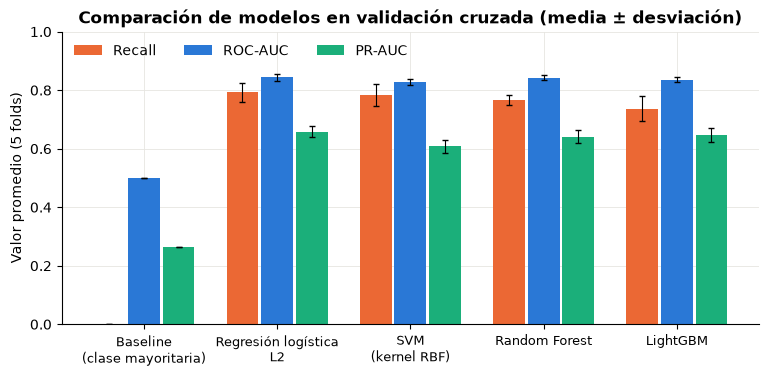

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
metr = [("recall", "Recall", NARANJA), ("roc_auc", "ROC-AUC", AZUL), ("pr_auc", "PR-AUC", AGUA)]
x = np.arange(len(tabla)); ancho = 0.26
for i, (m, etiqueta, color) in enumerate(metr):
    ax.bar(x + (i - 1) * ancho, tabla[f"{m}_media"], ancho * 0.92, yerr=tabla[f"{m}_desv"],
           color=color, label=etiqueta, capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(x); ax.set_xticklabels([m.replace(" (", "\n(").replace("logística ", "logística\n") for m in tabla["modelo"]], fontsize=9)
ax.set_ylabel("Valor promedio (5 folds)"); ax.set_ylim(0, 1)
ax.set_title("Comparación de modelos en validación cruzada (media ± desviación)")
ax.legend(frameon=False, ncol=3, loc="upper left")
guardar_figura(fig, "02_comparacion_modelos.png"); plt.show()

**Lectura.**
- El **baseline** (predecir siempre "no abandona") tiene una exactitud del **73.5 %** pero un **recall de 0**: no detecta a ningún cliente que se va. Esto muestra por qué la exactitud engaña aquí.
- Los cuatro modelos reales superan claramente al baseline (ROC-AUC entre 0.83 y 0.84 frente a 0.50).
- La **regresión logística L2** obtiene el mejor recall (**0.793 ± 0.033**), el mejor ROC-AUC (**0.845**) y el mejor PR-AUC (**0.658**).
- **LightGBM con parámetros por defecto** tiene el recall más bajo de los cuatro (0.737) aunque la mayor precisión (0.545): sin ajustar, es el más conservador.
- Las diferencias entre los modelos son pequeñas (pocas centésimas) y del orden de una o dos desviaciones estándar.

## 6. Elección del mejor modelo

Regla decidida **antes** de mirar el test: gana el mayor recall promedio entre los modelos que superan al baseline; si dos modelos están a menos de una desviación estándar, se desempata por PR-AUC y, si sigue el empate, se prefiere el más simple.

In [9]:
candidatos = tabla[tabla["modelo"] != "Baseline (clase mayoritaria)"].sort_values("recall_media", ascending=False)
lider = candidatos.iloc[0]
cercanos = candidatos[candidatos["recall_media"] >= lider["recall_media"] - lider["recall_desv"]]
mejor_nombre = cercanos.sort_values("pr_auc_media", ascending=False).iloc[0]["modelo"]
print("Modelos dentro de 1 desviación del líder en recall:", cercanos["modelo"].tolist())
print("Mejor modelo del Producto 1:", mejor_nombre)

Modelos dentro de 1 desviación del líder en recall: ['Regresión logística L2', 'SVM (kernel RBF)', 'Random Forest']
Mejor modelo del Producto 1: Regresión logística L2


**Lectura.** Solo la regresión logística (0.793) y la SVM (0.783) quedan dentro de una desviación estándar del mejor recall; entre las dos, la regresión logística tiene mayor PR-AUC (0.658 frente a 0.608) y además es el modelo más simple e interpretable. **Mejor modelo del Producto 1: regresión logística L2 con `class_weight="balanced"`.**

## 7. Evaluación única en el test

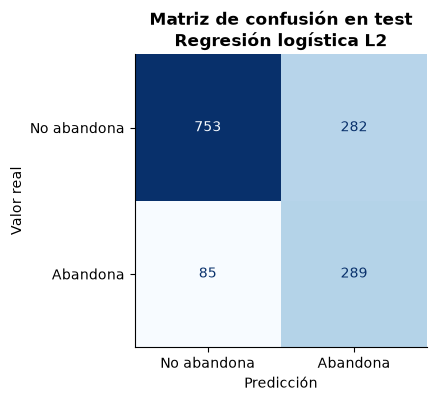

{'modelo': 'Regresión logística L2',
 'recall': 0.7727,
 'precision': 0.5061,
 'roc_auc': 0.8385,
 'pr_auc': 0.6277,
 'f1': 0.6116,
 'accuracy': 0.7395,
 'matriz_confusion': {'vn': 753, 'fp': 282, 'fn': 85, 'vp': 289}}

In [10]:
from sklearn.metrics import (recall_score, precision_score, roc_auc_score, average_precision_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
mejor = construir_pipeline(modelos_producto1()[mejor_nombre]).fit(X_train, y_train)
pred = mejor.predict(X_test)
puntaje = mejor.predict_proba(X_test)[:, 1] if hasattr(mejor, "predict_proba") else mejor.decision_function(X_test)
mc = confusion_matrix(y_test, pred)
test_p1 = {"modelo": mejor_nombre,
           "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
           "roc_auc": roc_auc_score(y_test, puntaje), "pr_auc": average_precision_score(y_test, puntaje),
           "f1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred),
           "matriz_confusion": {"vn": int(mc[0, 0]), "fp": int(mc[0, 1]), "fn": int(mc[1, 0]), "vp": int(mc[1, 1])}}
test_p1 = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in test_p1.items()}
guardar_json(test_p1, "02_test_mejor_modelo.json")

fig, ax = plt.subplots(figsize=(4.4, 3.8))
ConfusionMatrixDisplay(mc, display_labels=["No abandona", "Abandona"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en test\n{mejor_nombre}"); ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
ax.grid(False)
guardar_figura(fig, "02_matriz_confusion_test.png"); plt.show()
test_p1

**Lectura (test, usado una sola vez).** En los 1 409 clientes del test, la regresión logística detecta **289 de los 374 que abandonan (recall = 0.773)**, con ROC-AUC 0.839 y PR-AUC 0.628. El precio es de **282 falsas alarmas**: la precisión es 0.506 (aprox. una de cada dos alertas es correcta). Los valores son cercanos a los de la validación cruzada (recall 0.793 ± 0.033), así que no hay señales de sobreajuste. Para el negocio: de cada 100 clientes que se iban a ir, el modelo avisa a tiempo de unos 77.

## Conclusiones

1. Con un Pipeline que aprende el preprocesamiento solo con datos de entrenamiento, **los cuatro modelos superan ampliamente al baseline** (ROC-AUC 0.83–0.84 frente a 0.50).
2. **La regresión logística L2 es el mejor modelo del Producto 1** (recall CV 0.793, ROC-AUC 0.845, PR-AUC 0.658); en el test logra recall 0.773 y ROC-AUC 0.839.
3. LightGBM sin ajustar es el que menos detecta (recall 0.737): queda pendiente ver en el Producto 2 si la optimización de hiperparámetros cambia esto.
4. `cargo_total` se excluye por redundante, y `id_cliente` por ser un identificador.